### Import libraries

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import load_model

### Define class names

In [2]:
CLASSES = [
    'Tomato_Bacterial_spot',
    'Tomato_Early_blight',
    'Tomato_Late_blight',
    'Tomato_Leaf_Mold',
    'Tomato_healthy'
]

IMG_SIZE = (224, 224)

### Load trained models

In [3]:
custom_cnn = load_model(
    "../models/custom_cnn.keras"
)

mobilenet = load_model(
    "../models/mobilenetv2.keras"
)

print("Both models loaded successfully!")

Both models loaded successfully!


### Load and display a leaf image

In [4]:
image_path = "../dataset/raw/Tomato_healthy/"

import os

image_files = os.listdir(image_path)

print("Available images:", len(image_files))
print("First image:", image_files[0])

Available images: 1591
First image: 000146ff-92a4-4db6-90ad-8fce2ae4fddd___GH_HL Leaf 259.1.JPG


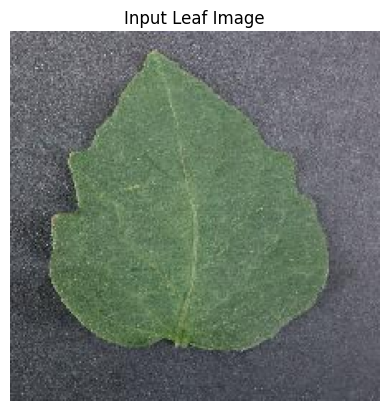

In [5]:
image_path = os.path.join(
    image_path,
    image_files[0]
)

img = image.load_img(
    image_path,
    target_size=IMG_SIZE
)

plt.imshow(img)
plt.axis("off")
plt.title("Input Leaf Image")
plt.show()

### Preprocess the image

In [6]:
img_array = image.img_to_array(img)

img_array = np.expand_dims(
    img_array,
    axis=0
)

custom_input = img_array / 255.0

In [7]:
mobile_input = preprocess_input(
    img_array.copy()
)

### Create prediction function

In [8]:
def predict_disease(model, processed_image):

    predictions = model.predict(
        processed_image,
        verbose=0
    )

    predicted_index = np.argmax(
        predictions[0]
    )

    predicted_class = CLASSES[predicted_index]

    confidence = predictions[0][predicted_index] * 100

    return predicted_class, confidence, predictions[0]

### Predict using both models

###### Custom CNN:

In [9]:
custom_result = predict_disease(
    custom_cnn,
    custom_input
)

print("Custom CNN Prediction:", custom_result[0])
print("Confidence:", round(custom_result[1], 2), "%")

Custom CNN Prediction: Tomato_healthy
Confidence: 100.0 %


###### MobileNetV2

In [10]:
mobile_result = predict_disease(
    mobilenet,
    mobile_input
)

print("MobileNetV2 Prediction:", mobile_result[0])
print("Confidence:", round(mobile_result[1], 2), "%")

MobileNetV2 Prediction: Tomato_healthy
Confidence: 99.98 %


### Compare prediction results

In [11]:
print("CUSTOM CNN")
print("----------------------")
print("Disease:", custom_result[0])
print("Confidence:", round(custom_result[1], 2), "%")

print("\nMOBILENETV2")
print("----------------------")
print("Disease:", mobile_result[0])
print("Confidence:", round(mobile_result[1], 2), "%")

CUSTOM CNN
----------------------
Disease: Tomato_healthy
Confidence: 100.0 %

MOBILENETV2
----------------------
Disease: Tomato_healthy
Confidence: 99.98 %


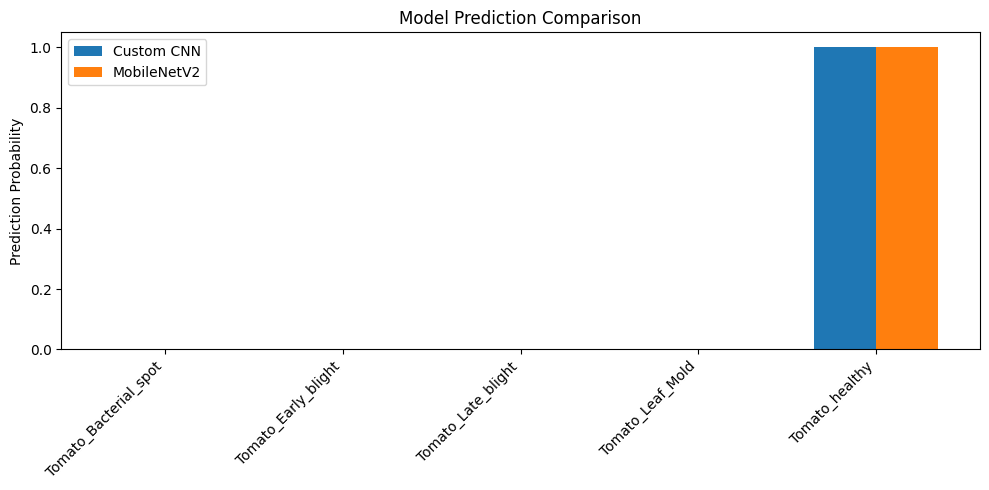

In [12]:
plt.figure(figsize=(10, 5))

x = np.arange(len(CLASSES))
width = 0.35

plt.bar(
    x - width/2,
    custom_result[2],
    width,
    label="Custom CNN"
)

plt.bar(
    x + width/2,
    mobile_result[2],
    width,
    label="MobileNetV2"
)

plt.xticks(
    x,
    CLASSES,
    rotation=45,
    ha="right"
)

plt.ylabel("Prediction Probability")
plt.title("Model Prediction Comparison")

plt.legend()
plt.tight_layout()
plt.show()